# Semantic Segmentation

---

## Dataset Preparation

In [1]:
# Setup

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.models import Model

data_dir = Path.cwd() / "data"

I0000 00:00:1792221339.749282   28291 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792221339.802021   28291 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792221340.850002   28291 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Collecting image paths

records = []

for image_path in sorted(data_dir.glob("*/*.tif")):
    # Skipping masks, saving image and mask together
    if image_path.stem.endswith("_mask"):
        continue

    # Gettings mask patah from image name
    mask_path = image_path.with_name(f"{image_path.stem}_mask.tif")
    if not mask_path.is_file():
        raise FileNotFoundError(f"Missing mask: {mask_path}")

    records.append(
        {
            "patient_id": image_path.parent.name,  # Patient id is folder name i think
            "image_id": image_path.stem,
            "image_path": str(image_path),
            "mask_path": str(mask_path),
        }
    )

In [3]:
# Converting to pandas

data_df = pd.DataFrame(records)
print(f"Number of patients: {data_df['patient_id'].nunique()}")
print(f"Number of image-mask pairs: {len(data_df)}")

display(data_df.head())

Number of patients: 110
Number of image-mask pairs: 3929


,patient_id,image_id,image_path,mask_path
0,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_1,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,/mnt/c/dev/repos/Semantic Segmentation/data/TC...
1,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_10,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,/mnt/c/dev/repos/Semantic Segmentation/data/TC...
2,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_11,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,/mnt/c/dev/repos/Semantic Segmentation/data/TC...
3,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_12,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,/mnt/c/dev/repos/Semantic Segmentation/data/TC...
4,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_13,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,/mnt/c/dev/repos/Semantic Segmentation/data/TC...


In [4]:
# Inspecting images

# Grabbing first pair of images
sample = data_df.iloc[0]
with Image.open(sample["image_path"]) as image_file:
    image = np.array(image_file)
with Image.open(sample["mask_path"]) as mask_file:
    mask = np.array(mask_file)
    
print(f"Image shape: {image.shape}")
print(f"Image data type: {image.dtype}")
print(f"Image pixel range: {image.min()} to {image.max()}")

print(f"\nMask shape: {mask.shape}")
print(f"Mask data type: {mask.dtype}")
print(f"Unique mask values: {np.unique(mask)}")

Image shape: (256, 256, 3)
Image data type: uint8
Image pixel range: 0 to 215

Mask shape: (256, 256)
Mask data type: uint8
Unique mask values: [0]


In [5]:
# Identifying any images with abnormalities from masks
# If any white pixels in mask, abnormalities present

has_abnormality = []

for mask_path in data_df["mask_path"]:
    with Image.open(mask_path) as mask_file:
        mask = np.array(mask_file)
        
    has_abnormality.append(bool(np.any(mask > 0))) # If any are non zero
    
data_df["has_abnormality"] = has_abnormality

print(f"Masks with abnormalities found:    {data_df['has_abnormality'].sum()}")
print(f"Masks without abnormalities found: {(~data_df['has_abnormality']).sum()}")

Masks with abnormalities found:    1373
Masks without abnormalities found: 2556


In [6]:
# Final Dataset Inspection
# Images will be loaded from paths as needed for memory

display(data_df.head())
display(data_df.describe())

,patient_id,image_id,image_path,mask_path,has_abnormality
0,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_1,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,False
1,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_10,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,False
2,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_11,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,True
3,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_12,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,True
4,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_13,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,True


,patient_id,image_id,image_path,mask_path,has_abnormality
count,3929,3929,3929,3929,3929
unique,110,3929,3929,3929,2
top,TCGA_HT_A61A_20000127,TCGA_CS_4941_19960909_1,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,/mnt/c/dev/repos/Semantic Segmentation/data/TC...,False
freq,88,1,1,1,2556


## Data visualization

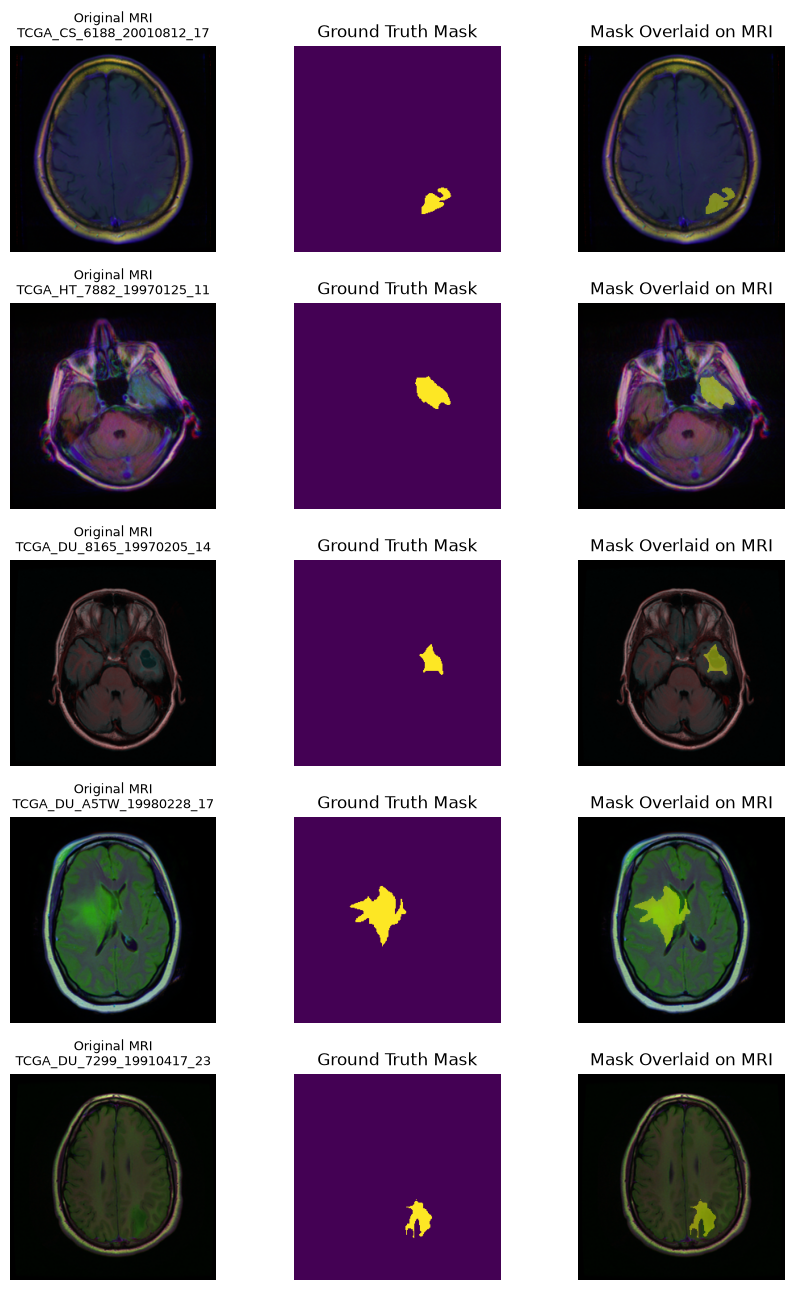

In [7]:
# Viewing images and their masks

# Getting all rows where mask has abnormality
abnormal_masks = data_df[data_df["has_abnormality"]]

examples = (
    abnormal_masks
    .groupby("patient_id", group_keys=False) # Group rows by patient
    .sample(n=1, random_state=24)            # Choose one mask from each patient
    .sample(n=5, random_state=24)            # Choose 5 masks from the last result
)

fig, axes = plt.subplots(5, 3, figsize=(9, 13))
for row_idx, (_, sample) in enumerate(examples.iterrows()):
    # Loading original images
    with Image.open(sample["image_path"]) as image_file:
        image = np.array(image_file)
    with Image.open(sample["mask_path"]) as mask_file:
            mask = np.array(mask_file)
            
    # Display original
    axes[row_idx, 0].imshow(image)
    axes[row_idx, 0].set_title(
        f"Original MRI\n{sample['image_id']}", fontsize=9
    )
    
    # Display mask
    axes[row_idx, 1].imshow(mask)
    axes[row_idx, 1].set_title("Ground Truth Mask")
    
    # Display overlaid
    
    # Hiding bg pixels so they don't cover image
    binary_mask = mask > 0
    overlay_mask = np.ma.masked_where(~binary_mask, binary_mask)
    
    axes[row_idx, 2].imshow(image)
    axes[row_idx, 2].imshow(
        overlay_mask,
        cmap="autumn",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    axes[row_idx, 2].set_title("Mask Overlaid on MRI")
    
    for axis in axes[row_idx]:
        axis.axis("off")
        
plt.tight_layout()
plt.show()

## Dataset Preprocessing

In [8]:
# Splitting into training, validation and test

# Splitting data based on patients rather than images
# 70% training, 15% validation, 15% test
patient_ids = np.array(sorted(data_df["patient_id"].unique()))
rng = np.random.default_rng(seed=24) # Need to be able to reproduce splits
rng.shuffle(patient_ids)

# Calculating splits
train_end = int(0.70 * len(patient_ids))
val_end = train_end + int(0.15 * len(patient_ids))

train_patient_ids = patient_ids[:train_end]
val_patient_ids = patient_ids[train_end:val_end]
test_patient_ids = patient_ids[val_end:]

# Assign all images to set containing their patient
train_df = (
    data_df[data_df["patient_id"].isin(train_patient_ids)].copy().reset_index(drop=True)
)
val_df = (
    data_df[data_df["patient_id"].isin(val_patient_ids)].copy().reset_index(drop=True)
)
test_df = (
    data_df[data_df["patient_id"].isin(test_patient_ids)].copy().reset_index(drop=True)
)

# Check that no patient appears in more than one df
if(
    not set(train_patient_ids).isdisjoint(val_patient_ids)
    or not set(train_patient_ids).isdisjoint(test_patient_ids)
    or not set(val_patient_ids).isdisjoint(test_patient_ids)
):
    raise ValueError("A patient appears in more than one set.")

# Looking at the splits
split_summary = pd.DataFrame(
    [
        {
            "split": name,
            "patients": frame["patient_id"].nunique(),
            "slices": len(frame),
            "slices_with_abnormality": frame["has_abnormality"].sum(),
            "abnormality_percentage": round(frame["has_abnormality"].mean() * 100, 1),
        }
        for name, frame in [
            ("Training", train_df),
            ("Validation", val_df),
            ("Test", test_df),
        ]
    ]
)
display(split_summary)

,split,patients,slices,slices_with_abnormality,abnormality_percentage
0,Training,77,2792,982,35.2
1,Validation,16,492,179,36.4
2,Test,17,645,212,32.9


In [9]:
# Preparing image mask pairs

def load_images(image_path, mask_path):
    """Preps image and mask pair for augmentation"""
    with Image.open(image_path) as image_file:
        image = np.array(image_file).astype(np.float32)
        
    # Making sure mask is binary floats
    with Image.open(mask_path) as mask_file:
        mask = (np.array(mask_file) > 0).astype(np.float32)
    # Adding a channel for model output
    mask = mask[..., np.newaxis]
    
    # Could resize but i don't think needed for this dataset
        
    return image, mask
    
sample = train_df.iloc[0]
image,mask = load_images(sample["image_path"], sample["mask_path"])
print(f"Image shape: {image.shape}, dtype: {image.dtype}")
print(f"Image range: {image.min():.3f} to {image.max():.3f}")
print(f"Mask shape: {mask.shape}, dtype: {mask.dtype}")
print(f"Mask values: {np.unique(mask)}")


Image shape: (256, 256, 3), dtype: float32
Image range: 0.000 to 215.000
Mask shape: (256, 256, 1), dtype: float32
Mask values: [0.]


In [10]:
# Augmentation

# Need to augment image and mask the same way
aug_settings = {
    "rotation_range" : 15,
    "width_shift_range" : 0.05,
    "height_shift_range" : 0.05,
    "zoom_range" : 0.10,
    "horizontal_flip" : True,
    "fill_mode" : "constant",
    "cval" : 0.0
}

image_gen = ImageDataGenerator(
    **aug_settings,
    rescale=1.0 / 255.0, # Change pixel vals to 0 - 1
    interpolation_order = 1
)

mask_gen = ImageDataGenerator(
    **aug_settings,
    interpolation_order = 0
)

Augmented image range: 0.000 to 0.929
Augmented mask values: [0. 1.]


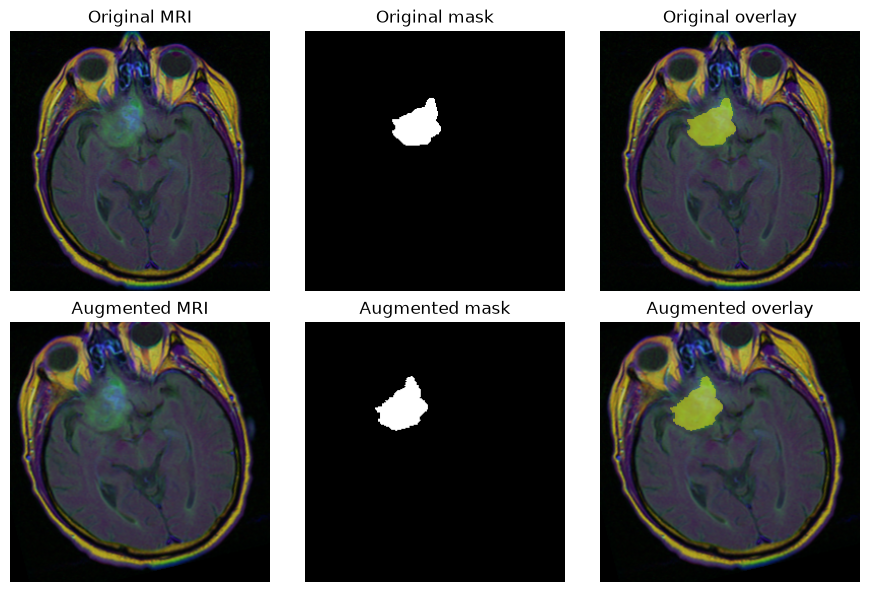

In [11]:
# Checking augmentation can be done to image and mask correctly

# Getting sample with an abnormality
sample = train_df[train_df["has_abnormality"]].iloc[0]
image, mask = load_images(sample["image_path"], sample["mask_path"])

# Getting one transform and applying to both
transform = image_gen.get_random_transform(image.shape, seed=24)
aug_image = image_gen.apply_transform(image.copy(), transform)
aug_mask = mask_gen.apply_transform(mask.copy(), transform)

# Rescale after 
aug_image = image_gen.standardize(aug_image)

print(f"Augmented image range: {aug_image.min():.3f} to {aug_image.max():.3f}")
print(f"Augmented mask values: {np.unique(aug_mask)}")

# Visualization
pairs = [
    (image / 255, mask, "Original"),
    (aug_image, aug_mask, "Augmented")
]

fig, axes = plt.subplots(2,3, figsize = (9, 6))
for row, (display_image, display_mask, label) in enumerate(pairs):
    binary_mask = display_mask[:,:,0] > 0
    
    axes[row, 0].imshow(display_image)
    axes[row, 0].set_title(f"{label} MRI")
    
    axes[row, 1].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title(f"{label} mask")
    
    overlay = np.ma.masked_where(~binary_mask, binary_mask)
    axes[row, 2].imshow(display_image)
    axes[row, 2].imshow(overlay, cmap="autumn", alpha=0.45, vmin=0, vmax=1)
    axes[row, 2].set_title(f"{label} overlay")
    
    for axis in axes[row]:
        axis.axis("off")
        
        
plt.tight_layout()
plt.show()

In [12]:
# Batch loader for training and eval

class SegmentationDataset(tf.keras.utils.PyDataset): # Keras can use this
    def __init__(
        self, dataframe, image_generator, mask_generator,
        batch_size=8, augment=False, shuffle=False, seed=24
    ):
        super().__init__()
        
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_generator = image_generator
        self.mask_generator = mask_generator
        self.batch_size = batch_size
        self.augment = augment
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(self.dataframe))
        
        # Suffling
        if self.shuffle:
            self.rng.shuffle(self.indices)
        
    def __len__(self):
        """Get number of batches"""
        return(len(self.dataframe) + self.batch_size - 1) // self.batch_size
    
    def __getitem__(self, batch_index):
        """Load and prep image mask pairs for one batch"""
        start = batch_index * self.batch_size
        batch_indices = self.indices[start:start + self.batch_size]
        images, masks = [], []
        
        for index in batch_indices:
            sample = self.dataframe.iloc[index]
            image,mask = load_images(
                sample["image_path"], sample["mask_path"]
            )
            
            # Apply same transformes to mask and image
            if self.augment:
                transform = self.image_generator.get_random_transform(
                    image.shape
                )
                image = self.image_generator.apply_transform(image, transform)
                mask = self.mask_generator.apply_transform(mask, transform)
                
            image = self.image_generator.standardize(image)
            mask = self.mask_generator.standardize(mask)
            
            images.append(image)
            masks.append(mask)
        
        return np.stack(images), np.stack(masks)
    
    def on_epoch_end(self):
        """If set to shuffle, will shuffle after each complete pass of dataset."""
        if self.shuffle:
            self.rng.shuffle(self.indices)

In [13]:
# Training set loader

tf.keras.utils.set_random_seed(24)

train_dataset = SegmentationDataset(
    train_df,
    image_gen,
    mask_gen,
    batch_size=8,
    augment=True,
    shuffle=True
)

# Looking at a batch
batch_images, batch_masks = train_dataset[0]
print(f"Training batches: {len(train_dataset)}")
print(f"Image batch shape: {batch_images.shape}")
print(f"Mask batch shape: {batch_masks.shape}")
print(f"Image range: {batch_images.min()} to {batch_images.max()}")
print(f"Mask values: {np.unique(batch_masks)}")

Training batches: 349
Image batch shape: (8, 256, 256, 3)
Mask batch shape: (8, 256, 256, 1)
Image range: 0.0 to 0.9777360558509827
Mask values: [0. 1.]


In [14]:
# Validation dataset and augmentation

# Use these for no augmentation
eval_image_gen = ImageDataGenerator(rescale=1.0 / 255.0)
eval_mask_gen = ImageDataGenerator()

# Keeping unchanged images for early stopping 
val_dataset = SegmentationDataset(
    val_df,
    eval_image_gen,
    eval_mask_gen,
    batch_size=8,
    augment=False,
    shuffle=False
)

# Augmented version, going to do seperate test on both val sets
# as aug will change so results will be different each time
augmented_val_dataset = SegmentationDataset(
    val_df,
    image_gen,
    mask_gen,
    batch_size=8,
    augment=True,
    shuffle=False
)

# Test dataset is unchanged, just reusing same class, needs generators
test_dataset = SegmentationDataset(
    test_df,
    eval_image_gen,
    eval_mask_gen,
    batch_size=8,
    augment=False,
    shuffle=False
)

print(f"Validation batches: {len(val_dataset)}")
print(f"Augmented validation batches: {len(augmented_val_dataset)}")
print(f"Test batches: {len(test_dataset)}")


Validation batches: 62
Augmented validation batches: 62
Test batches: 81


## Model Design

In [15]:
# Custom autoencoder

# Model layout:
# input 256 -> 128 -> 64 -> bottleneck 32 -> 64 -> 128 -> restored 256 -> 1 abnormality prob per pixel

input_shape = (256, 256, 3)
input_layer = Input(shape=input_shape)

# Shrinking down
encoding_layer = Conv2D(16, 3, activation="relu", padding="same")(input_layer)
encoding_layer = MaxPooling2D(2)(encoding_layer)

encoding_layer = Conv2D(32, 3, activation="relu", padding="same")(encoding_layer)
encoding_layer = MaxPooling2D(2)(encoding_layer)

encoding_layer = Conv2D(64, 3, activation="relu", padding="same")(encoding_layer)
encoding_layer = MaxPooling2D(2)(encoding_layer)

# Bottleneck at 32x32
bottleneck_layer = Conv2D(128, 3, activation="relu", padding="same")(encoding_layer)

# Going back up
decoding_layer = UpSampling2D(2)(bottleneck_layer)
decoding_layer = Conv2D(64, 3, activation="relu", padding="same")(decoding_layer)

decoding_layer = UpSampling2D(2)(decoding_layer)
decoding_layer = Conv2D(32, 3, activation="relu", padding="same")(decoding_layer)

decoding_layer = UpSampling2D(2)(decoding_layer)
decoding_layer = Conv2D(16, 3, activation="relu", padding="same")(decoding_layer)

# Prediction
output_layer = Conv2D(1, 1, activation="sigmoid", padding="same")(decoding_layer)

# Put model together
custom_autoencoder = Model(input_layer, output_layer)
custom_autoencoder.summary()

I0000 00:00:1792221376.044013   28291 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 256, 256, 16)   │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 256, 256, 1)    │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 194,337 (759.13 KB)

 Trainable params: 194,337 (759.13 KB)

 Non-trainable params: 0 (0.00 B)

## Model Training

In [16]:
# Loss functions

# Dice
# def dice_coefficient(y_true, y_pred):
#     y_true = tf.cast(y_true, tf.float32)
#     y_pred = tf.cast(y_pred, tf.float32)  
#     axes = (1,2,3)
#     intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
#     total = (
#         tf.reduce_sum(y_true, axis=axes)
#         + tf.reduce_sum(y_pred, axis=axes)
#     )  
#     # Handle div by 0 and empty masks
#     # Empty mask with no abnormality overlap is always 0
#     # adding 1 to both sides gives dice = 1 when both masks are empty, giving signal still
#     smooth = 1.0
#     return (2.0 * intersection + smooth) / (total + smooth)

# def dice_loss(y_true, y_pred):
#     return 1.0 - dice_coefficient(y_true, y_pred)

dice_loss = tf.keras.losses.Dice(axis=None)

# Tversky
def tversky_index(y_true, y_pred, alpha=0.3, beta=0.7):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    
    axes = (None) # Across batch not image
    tp = tf.reduce_sum(y_true * y_pred, axis=axes)
    fp = tf.reduce_sum((1.0 - y_true) * y_pred, axis=axes)
    fn = tf.reduce_sum(y_true * (1.0 - y_pred), axis=axes)
    
    # Handling div by 0 and empty mask
    smooth = 1.0
    return (tp + smooth) / (tp + alpha * fp + beta * fn + smooth)

def tversky_loss(y_true, y_pred):
    return 1.0 - tversky_index(y_true, y_pred)

def focal_tversky_loss(y_true, y_pred):
    loss = tversky_loss(y_true, y_pred)
    loss = tf.clip_by_value(loss, 1e-7, 1.0)
    return tf.pow(loss, 0.75)

### Custom Models

In [17]:
model_dir = Path.cwd() / "models"
history_dir = Path.cwd() / "history"
model_dir.mkdir(exist_ok=True)
history_dir.mkdir(exist_ok=True)

# Keeping starting weights for the different loss models
if not (model_dir/"custom_initial.weights.h5").exists():
    custom_autoencoder.save_weights(model_dir / "custom_initial.weights.h5")

In [18]:
# Custom dice loss model

custom_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=dice_loss,
    metrics=[tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
)

# Early stopping when no improvement in 8 epochs
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    mode="min",
    restore_best_weights=True
)

# Saving whe nloss improves
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(model_dir / "custom_dice.keras"),
    monitor="val_loss",
    mode="min",
    save_best_only=True
)

# Logging results
csv_logger = tf.keras.callbacks.CSVLogger(str(history_dir/"custom_dice.csv"))

In [19]:
# Training dice model

# Train only if file doesnt exist
if not (model_dir/"custom_dice.keras").exists():
    history_custom_dice = custom_autoencoder.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )
# Otherwise load trained model and history
else:
    custom_autoencoder = tf.keras.models.load_model(
        model_dir/"custom_dice.keras",
        compile=False
    )
    history_custom_dice = tf.keras.callbacks.History()
    history_custom_dice.history = (
        pd.read_csv(history_dir/"custom_dice.csv")
        .drop(columns="epoch")
        .to_dict("list")
    )
    print("Loaded saved dice model and history")

Loaded saved dice model and history


In [20]:
# Tversky model

if not (model_dir/"custom_tversky.keras").exists():
    custom_tversky = tf.keras.models.clone_model(custom_autoencoder)
    custom_tversky.load_weights(model_dir/"custom_initial.weights.h5")

    custom_tversky.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=tversky_loss,
        metrics = [tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )

    # Early stopping when no improvement in 8 epochs
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        mode="min",
        restore_best_weights=True
    )

    # Saving when loss improves
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=str(model_dir / "custom_tversky.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )

    # Logging results
    csv_logger = tf.keras.callbacks.CSVLogger(str(history_dir/"custom_tversky.csv"))

    # Train
    history_custom_tversky = custom_tversky.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )

else:
    # load already saved stuff
    custom_tversky = tf.keras.models.load_model(
        model_dir/"custom_tversky.keras",
        compile=False
    )
    history_custom_tversky = tf.keras.callbacks.History()
    history_custom_tversky.history = (
    pd.read_csv(history_dir/"custom_tversky.csv")
    .drop(columns="epoch")
    .to_dict("list"))
    
    print("Loaded saved tversky model and history")

Loaded saved tversky model and history


In [21]:
# Focal Tversky model

if not (model_dir/"custom_tversky.keras").exists():
    custom_focal_tversky = tf.keras.models.clone_model(custom_autoencoder)
    custom_focal_tversky.load_weights(model_dir/"custom_initial.weights.h5")

    custom_focal_tversky.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=focal_tversky_loss,
        metrics = [tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )

    # Early stopping when no improvement in 8 epochs
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        mode="min",
        restore_best_weights=True
    )

    # Saving when loss improves
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=str(model_dir / "custom_focal_tversky.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )

    # Logging results
    csv_logger = tf.keras.callbacks.CSVLogger(str(history_dir/"custom_focal_tversky.csv"))

    # Train
    history_custom_focal_tversky = custom_focal_tversky.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )

else:
    # load already saved stuff
    custom_focal_tversky = tf.keras.models.load_model(
        model_dir/"custom_focal_tversky.keras",
        compile=False
    )
    history_custom_focal_tversky = tf.keras.callbacks.History()
    history_custom_focal_tversky.history = (
    pd.read_csv(history_dir/"custom_focal_tversky.csv")
    .drop(columns="epoch")
    .to_dict("list"))
    
    print("Loaded saved tversky model and history")

Loaded saved tversky model and history


### Pretrained Model

In [22]:
# Base pretrained model

pretrained_base_model = tf.keras.applications.MobileNetV2(
    input_shape=(256, 256, 3),
    include_top=False,
    weights="imagenet"
)

# Using models already learned features
pretrained_base_model.trainable = False

pretrained_base_model.summary()

/tmp/ipykernel_28291/2826889179.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  pretrained_base_model = tf.keras.applications.MobileNetV2(


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 128, 128,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 128, 128,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 128, 128,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 128, 128,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 128, 128,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 128, 128,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 129, 129,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 64, 64,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 64, 64,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [23]:
# Creating encoder from pretrained model weights

# Layers we are grabbing outputs from
layer_names = [
    "block_1_expand_relu",  # 128 x 128
    "block_3_expand_relu",  # 64 x 64
    "block_6_expand_relu",  # 32 x 32
    "block_13_expand_relu", # 16 x 16
    "block_16_project",     # 8 x 8 Bottleneck
]

# Outputs from layers for skip connections and bottleneck
encoder_outputs = [
    pretrained_base_model.get_layer(name).output
    for name in layer_names
]

# Build the encoder
pretrained_encoder = tf.keras.Model(
    inputs=pretrained_base_model.input,
    outputs=encoder_outputs,
    name= "pretrained_encoder"
)

# Freeze pretrained weights
pretrained_encoder.trainable = False

# Checking encoder output shapes
for name, output in zip(layer_names, pretrained_encoder.outputs):
    print(f"{name}: {output.shape}")

input_layer = tf.keras.layers.Input(shape=(256, 256, 3))

# Rescale to expected input for MobileNetV2
encoder_input = tf.keras.layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(input_layer)

# Connect input to the encoder
skip_1, skip_2, skip_3, skip_4, bottleneck = pretrained_encoder(
    encoder_input,
    training=False
)

block_1_expand_relu: (None, 128, 128, 96)
block_3_expand_relu: (None, 64, 64, 144)
block_6_expand_relu: (None, 32, 32, 192)
block_13_expand_relu: (None, 16, 16, 576)
block_16_project: (None, 8, 8, 320)


In [24]:
# Decoder


# First decoder block
# Upsample bottle neck to 16x16
decoding_layer = tf.keras.layers.Conv2DTranspose(
    filters=512,
    kernel_size=3,
    strides=2,
    padding="same",
    use_bias=False
)(bottleneck)
decoding_layer = tf.keras.layers.BatchNormalization()(decoding_layer)
decoding_layer = tf.keras.layers.Activation("relu")(decoding_layer)
# Join upsample with encoders skip connections
decoding_layer = tf.keras.layers.Concatenate()(
    [decoding_layer, skip_4]
)

# 16x16 to 32x32
decoding_layer = tf.keras.layers.Conv2DTranspose(
    filters=256,
    kernel_size=3,
    strides=2,
    padding="same",
    use_bias=False
)(decoding_layer)
decoding_layer = tf.keras.layers.BatchNormalization()(decoding_layer)
decoding_layer = tf.keras.layers.Activation("relu")(decoding_layer)
decoding_layer = tf.keras.layers.Concatenate()(
    [decoding_layer, skip_3]
)

# 32x32 to 64x64
decoding_layer = tf.keras.layers.Conv2DTranspose(
    filters=128,
    kernel_size=3,
    strides=2,
    padding="same",
    use_bias=False
)(decoding_layer)
decoding_layer = tf.keras.layers.BatchNormalization()(decoding_layer)
decoding_layer = tf.keras.layers.Activation("relu")(decoding_layer)
# Join upsample with encoders skip connections
decoding_layer = tf.keras.layers.Concatenate()(
    [decoding_layer, skip_2]
)

# 64x64 to 128x128
decoding_layer = tf.keras.layers.Conv2DTranspose(
    filters=64,
    kernel_size=3,
    strides=2,
    padding="same",
    use_bias=False
)(decoding_layer)
decoding_layer = tf.keras.layers.BatchNormalization()(decoding_layer)
decoding_layer = tf.keras.layers.Activation("relu")(decoding_layer)
# Join upsample with encoders skip connections
decoding_layer = tf.keras.layers.Concatenate()(
    [decoding_layer, skip_1]
)

# 128x128 to 256x256, Final restoration with probability prediction per pixel
output_layer = tf.keras.layers.Conv2DTranspose(
    filters=1,
    kernel_size=3,
    strides=2,
    padding="same",
    activation="sigmoid"
)(decoding_layer)

In [25]:
# Assembling full u-net from decoder and encoder

pretrained_unet_model = tf.keras.Model(
    inputs=input_layer,
    outputs=output_layer,
    name="mobilenetv2_unet"
)

pretrained_unet_model.summary()

Model: "mobilenetv2_unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 256, 256,  │          0 │ input_layer_2[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pretrained_encoder  │ [(None, 128, 128, │  1,841,984 │ rescaling[0][0]   │
│ (Functional)        │ 96), (None, 64,   │            │                   │
│                     │ 64, 144), (None,  │            │                   │
│                     │ 32, 32, 192),     │            │                   │
│                     │ (None, 16, 16,    │            │                   │
│                     │ 576), (None, 8,   │            │                   │
│                     │ 8, 320)]          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │  1,474,560 │ pretrained_encod… │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 16, 16,    │      2,048 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ activation[0][0], │
│ (Concatenate)       │ 1088)             │            │ pretrained_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 32, 32,    │  2,506,752 │ concatenate[0][0] │
│ (Conv2DTranspose)   │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 32, 32,    │          0 │ activation_1[0][… │
│ (Concatenate)       │ 448)              │            │ pretrained_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 64, 64,    │    516,096 │ concatenate_1[0]… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 64, 64,    │          0 │ activation_2[0][… │
│ (Concatenate)       │ 272)              │            │ pretrained_encod

 Total params: 6,501,345 (24.80 MB)

 Trainable params: 4,657,441 (17.77 MB)

 Non-trainable params: 1,843,904 (7.03 MB)

In [26]:
# Saving initial weights for training all three loss models on same weights

unet_initial_path = model_dir/"pretrained_unet_initial.weights.h5"

if not unet_initial_path.exists():
    pretrained_unet_model.save_weights(unet_initial_path)
    print("Saved initial weights.")
else:
    pretrained_unet_model.load_weights(unet_initial_path)
    print("Loaded initial weights")

Saved initial weights.


In [27]:
# Training with Dice loss


unet_dice_path = model_dir/"pretrained_unet_dice.keras"
unet_dice_history_path = history_dir/"pretrained_unet_dice.csv"

if not (unet_dice_path).exists():
    pretrained_unet_dice_model = tf.keras.models.clone_model(pretrained_unet_model)
    
    # Starting from saved initial weights
    pretrained_unet_dice_model.load_weights(unet_initial_path)
    
    pretrained_unet_dice_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=dice_loss,
        metrics=[tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        mode="min",
        restore_best_weights=True
    )
    
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=unet_dice_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
    
    csv_logger = tf.keras.callbacks.CSVLogger(
        
        str(unet_dice_history_path)
    )
    
    history_unet_dice = pretrained_unet_dice_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )
    
    pretrained_unet_dice_model.load_weights(unet_dice_path) # Restore best iteration

else:
    # Loading best model
    pretrained_unet_dice_model = tf.keras.models.load_model(
        unet_dice_path,
        compile=False
    )
    history_unet_dice = tf.keras.callbacks.History()
    history_unet_dice.history = (
        pd.read_csv(unet_dice_history_path)
        .drop(columns="epoch")
        .to_dict("list")
    )
    
    print("Loaded saved pretrained unet dice model.")

Epoch 1/50


I0000 00:00:1792221381.148939   28291 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1792221384.244685   28541 service.cc:153] XLA service 0x750090036520 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792221384.244715   28541 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792221384.322797   28541 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792221385.040696   28541 cuda_dnn.cc:461] Loaded cuDNN version 92700
E0000 00:00:1792221390.061527   28541 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1792221398.406514   28541 device_compiler.h:208] Compiled cluster 

349/349 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - loss: 0.6846 - pixel_accuracy: 0.8936

E0000 00:00:1792221483.840794   28541 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


349/349 ━━━━━━━━━━━━━━━━━━━━ 106s 253ms/step - loss: 0.6846 - pixel_accuracy: 0.8936 - val_loss: 0.7005 - val_pixel_accuracy: 0.9931
Epoch 2/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 86s 245ms/step - loss: 0.3668 - pixel_accuracy: 0.9947 - val_loss: 0.6200 - val_pixel_accuracy: 0.9940
Epoch 3/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 84s 240ms/step - loss: 0.3319 - pixel_accuracy: 0.9950 - val_loss: 0.5863 - val_pixel_accuracy: 0.9942
Epoch 4/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 75s 216ms/step - loss: 0.3245 - pixel_accuracy: 0.9953 - val_loss: 0.5865 - val_pixel_accuracy: 0.9940
Epoch 5/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 78s 223ms/step - loss: 0.2995 - pixel_accuracy: 0.9954 - val_loss: 0.6040 - val_pixel_accuracy: 0.9944
Epoch 6/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 75s 215ms/step - loss: 0.2838 - pixel_accuracy: 0.9956 - val_loss: 0.5799 - val_pixel_accuracy: 0.9946
Epoch 7/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 75s 213ms/step - loss: 0.2870 - pixel_accuracy: 0.9957 - val_loss: 0.5794 - val_pixel_accuracy: 0.9947
Epoch 8/5

In [28]:
# Training with Tversky loss

unet_tversky_path = model_dir/"pretrained_unet_tversky.keras"
unet_tversky_history_path = history_dir/"pretrained_unet_tversky.csv"

if not (unet_tversky_path).exists():
    pretrained_unet_tversky_model = tf.keras.models.clone_model(pretrained_unet_model)
    
    # Starting from saved initial weights
    pretrained_unet_tversky_model.load_weights(unet_initial_path)
    
    pretrained_unet_tversky_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=tversky_loss,
        metrics=[tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        mode="min",
        restore_best_weights=True
    )
    
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=unet_tversky_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
    
    csv_logger = tf.keras.callbacks.CSVLogger(
        
        str(unet_tversky_history_path)
    )
    
    history_unet_tversky = pretrained_unet_tversky_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )
    
    pretrained_unet_tversky_model.load_weights(unet_tversky_path) # Restore best iteration

else:
    # Loading best model
    pretrained_unet_tversky_model = tf.keras.models.load_model(
        unet_tversky_path,
        compile=False
    )
    history_unet_tversky = tf.keras.callbacks.History()
    history_unet_tversky.history = (
        pd.read_csv(unet_tversky_history_path)
        .drop(columns="epoch")
        .to_dict("list")
    )
    
    print("Loaded saved pretrained unet tversky model.")

Epoch 1/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 98s 261ms/step - loss: 0.6485 - pixel_accuracy: 0.8963 - val_loss: 0.6308 - val_pixel_accuracy: 0.9926
Epoch 2/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 111s 318ms/step - loss: 0.3551 - pixel_accuracy: 0.9940 - val_loss: 0.5991 - val_pixel_accuracy: 0.9906
Epoch 3/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 115s 328ms/step - loss: 0.3122 - pixel_accuracy: 0.9945 - val_loss: 0.5886 - val_pixel_accuracy: 0.9931
Epoch 4/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 113s 323ms/step - loss: 0.2860 - pixel_accuracy: 0.9949 - val_loss: 0.5707 - val_pixel_accuracy: 0.9933
Epoch 5/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 107s 307ms/step - loss: 0.2944 - pixel_accuracy: 0.9947 - val_loss: 0.6056 - val_pixel_accuracy: 0.9941
Epoch 6/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 147s 422ms/step - loss: 0.2658 - pixel_accuracy: 0.9952 - val_loss: 0.5645 - val_pixel_accuracy: 0.9941
Epoch 7/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 125s 354ms/step - loss: 0.2709 - pixel_accuracy: 0.9952 - val_loss: 0.5446 - val_pixel_accuracy: 

In [29]:
# Training with focal Tversky loss

unet_focal_tversky_path = model_dir/"pretrained_unet_focal_tversky.keras"
unet_focal_tversky_history_path = history_dir/"pretrained_unet_focal_tversky.csv"

if not (unet_focal_tversky_path).exists():
    pretrained_unet_focal_tversky_model = tf.keras.models.clone_model(pretrained_unet_model)

    # Starting from saved initial weights
    pretrained_unet_focal_tversky_model.load_weights(unet_initial_path)
    
    pretrained_unet_focal_tversky_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss=focal_tversky_loss,
        metrics=[tf.keras.metrics.BinaryAccuracy(name="pixel_accuracy")]
    )
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        mode="min",
        restore_best_weights=True
    )
    
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=unet_focal_tversky_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
    
    csv_logger = tf.keras.callbacks.CSVLogger(
        
        str(unet_focal_tversky_history_path)
    )
    
    history_unet_focal_tversky = pretrained_unet_focal_tversky_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stopping, checkpoint, csv_logger],
        shuffle=False
    )
    
    pretrained_unet_focal_tversky_model.load_weights(unet_focal_tversky_path) # Restore best iteration

else:
    # Loading best model
    pretrained_unet_focal_tversky_model = tf.keras.models.load_model(
        unet_focal_tversky_path,
        compile=False
    )
    history_unet_focal_tversky = tf.keras.callbacks.History()
    history_unet_focal_tversky.history = (
        pd.read_csv(unet_focal_tversky_history_path)
        .drop(columns="epoch")
        .to_dict("list")
    )
    
    print("Loaded saved pretrained unet focal tversky model.")

Epoch 1/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 135s 365ms/step - loss: 0.6955 - pixel_accuracy: 0.8932 - val_loss: 0.6957 - val_pixel_accuracy: 0.9931
Epoch 2/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 124s 356ms/step - loss: 0.4484 - pixel_accuracy: 0.9939 - val_loss: 0.6490 - val_pixel_accuracy: 0.9913
Epoch 3/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 123s 353ms/step - loss: 0.4188 - pixel_accuracy: 0.9944 - val_loss: 0.6422 - val_pixel_accuracy: 0.9935
Epoch 4/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 125s 357ms/step - loss: 0.3962 - pixel_accuracy: 0.9947 - val_loss: 0.6293 - val_pixel_accuracy: 0.9937
Epoch 5/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 122s 349ms/step - loss: 0.3689 - pixel_accuracy: 0.9951 - val_loss: 0.6328 - val_pixel_accuracy: 0.9939
Epoch 6/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 124s 354ms/step - loss: 0.3464 - pixel_accuracy: 0.9952 - val_loss: 0.6131 - val_pixel_accuracy: 0.9936
Epoch 7/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 120s 344ms/step - loss: 0.3419 - pixel_accuracy: 0.9956 - val_loss: 0.6038 - val_pixel_accuracy:

## Model Evaluation